# AValidate · Vision Experiment: MobileNet-V3 Baseline (10 Epochs)
### Lightweight Vision Baseline (~1.2M Parameters)

Standard vision baseline using MobileNet-V3 Small. Balances speed and accuracy on local machines.

---
**Hypothesis:** Lightweight MobileNet-V3 Small achieves strong baseline event discrimination with minimal compute overhead.

- **Run ID:** `mobilenet_10ep_v1`
- **Backbone:** `mobilenet_v3_small`
- **Epochs:** `10` | **Batch Size:** `8` | **Learning Rate:** `5e-4`
- **Loss Weighting:** `sqrt`
- **Artifacts Directory:** `_local/drive/artifacts/vision_baseline/mobilenet_10ep_v1/`
- **Embeddings Directory:** `_local/drive/embeddings/mobilenet_10ep_v1/`
---


## 0 · Environment & Hardware Check
Detects local Intel Arc 140V XPU GPU or CPU compute.


In [1]:
import os, sys
import torch

# Force unbuffered streaming output for subprocesses
os.environ["PYTHONUNBUFFERED"] = "1"

# Ensure notebook runs from repository root
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
os.chdir(REPO_ROOT)
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from vision import config as C

print(f"Working directory: {REPO_ROOT}")
print(f"PyTorch version:   {torch.__version__}")

has_xpu = hasattr(torch, 'xpu') and torch.xpu.is_available()
has_cuda = torch.cuda.is_available()
if has_cuda:
    device_desc = f"NVIDIA CUDA GPU ({torch.cuda.get_device_name(0)})"
elif has_xpu:
    device_desc = f"Intel Arc XPU GPU: {torch.xpu.get_device_name(0)}"
else:
    device_desc = f"CPU ({torch.get_num_threads()} threads)"

print(f"Active compute:    {device_desc}")
print(f"Artifacts root:    {C.ARTIFACT_DIR}")
print(f"Embeddings root:   {C.EMBED_DIR}")


Working directory: e:\GitHub-not sorted\NUS-AIS-GCs\Audio-Video-Confidence
PyTorch version:   2.14.1+xpu
Active compute:    Intel Arc XPU GPU: Intel(R) Arc(TM) 140V GPU (16GB)
Artifacts root:    E:\GitHub-not sorted\NUS-AIS-GCs\Audio-Video-Confidence\_local\drive\artifacts\vision_baseline
Embeddings root:   E:\GitHub-not sorted\NUS-AIS-GCs\Audio-Video-Confidence\_local\drive\embeddings


## 1 · Weights & Biases Experiment Tracking
Reads API credentials safely from `.env` and logs to `GC2-AValidate/avalidate`.


In [2]:
from pathlib import Path

env_file = Path(REPO_ROOT) / '.env'
if env_file.exists():
    for line in env_file.read_text(encoding='utf-8').splitlines():
        if '=' in line and not line.strip().startswith('#'):
            k, v = line.strip().split('=', 1)
            os.environ[k.strip()] = v.strip()

WANDB_ENTITY = os.environ.get('WANDB_ENTITY', 'GC2-AValidate')
WANDB_PROJECT = os.environ.get('WANDB_PROJECT', 'avalidate')
api_key = os.environ.get('WANDB_API_KEY', '')

try:
    import wandb
    if api_key:
        os.environ['WANDB_ENTITY'] = WANDB_ENTITY
        os.environ['WANDB_PROJECT'] = WANDB_PROJECT
        wandb.login(key=api_key)
        WANDB = '--wandb'
        print(f"W&B is ON: logging to {WANDB_ENTITY}/{WANDB_PROJECT} (group='vision')")
    else:
        WANDB = ''
        print("W&B is OFF (WANDB_API_KEY missing)")
except Exception as e:
    WANDB = ''
    print("W&B is OFF:", e)


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: C:\Users\swara\_netrc
wandb: Currently logged in as: s3arajgupta (GC2-AValidate) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B is ON: logging to GC2-AValidate/avalidate (group='vision')


## 2 · Verify Dataset & Cached Features
Verifies that extracted video frames and label metadata exist locally.


In [3]:
!python -u -m vision.data_ave
!python -u -m vision.features


Categories: 28
Annotations: 4143 over 4097 videos (45 videos annotated more than once)
Videos found: 4097
train: 3339 samples, 0 missing videos
val  : 402 samples, 0 missing videos
test : 402 samples, 0 missing videos
Videos shared by train&val: 10
Videos shared by train&test: 8
Videos shared by val&test: 0
train: y (3339, 10), yclip (3339,), ids 3339
val: y (402, 10), yclip (402,), ids 402
test: y (402, 10), yclip (402,), ids 402
norm_stats.json written to E:\GitHub-not sorted\NUS-AIS-GCs\Audio-Video-Confidence\_local\drive\cache\vision_features_v1\norm_stats.json


## 3 · Train Vision Model: `mobilenet_10ep_v1`
Trains `mobilenet_v3_small` for `10` epochs with cosine learning rate scheduling.


In [4]:
RUN_ID = 'mobilenet_10ep_v1'
BACKBONE = 'mobilenet_v3_small'
EPOCHS = 10
BATCH = 8
LR = '5e-4'
BALANCE = 'sqrt'

!python -u -m vision.train --run-id {RUN_ID} --backbone {BACKBONE} --epochs {EPOCHS} --batch {BATCH} --lr {LR} --balance {BALANCE} --workers 0 {WANDB}


device=xpu backbone=mobilenet_v3_small train=3339 val=402 params=1,237,309
ep 01 loss 2.200 | val sec-acc 0.473 sec-F1 0.452 clip-acc 0.590 clip-F1 0.543 | 118s
ep 02 loss 1.582 | val sec-acc 0.527 sec-F1 0.526 clip-acc 0.647 clip-F1 0.608 | 93s
ep 03 loss 1.352 | val sec-acc 0.525 sec-F1 0.531 clip-acc 0.684 clip-F1 0.652 | 117s
ep 04 loss 1.137 | val sec-acc 0.547 sec-F1 0.550 clip-acc 0.692 clip-F1 0.667 | 112s
ep 05 loss 0.956 | val sec-acc 0.569 sec-F1 0.587 clip-acc 0.721 clip-F1 0.705 | 143s
ep 06 loss 0.824 | val sec-acc 0.586 sec-F1 0.590 clip-acc 0.741 clip-F1 0.720 | 145s
ep 07 loss 0.695 | val sec-acc 0.596 sec-F1 0.610 clip-acc 0.751 clip-F1 0.735 | 162s
ep 08 loss 0.611 | val sec-acc 0.602 sec-F1 0.618 clip-acc 0.774 clip-F1 0.765 | 162s
ep 09 loss 0.548 | val sec-acc 0.604 sec-F1 0.623 clip-acc 0.774 clip-F1 0.763 | 127s
ep 10 loss 0.520 | val sec-acc 0.605 sec-F1 0.622 clip-acc 0.774 clip-F1 0.762 | 160s
best val per-second macro-F1: 0.623  ->  E:\GitHub-not sorted\NUS-

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: s3arajgupta (GC2-AValidate) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wandb: setting up run 32ug1tx1
wandb: Tracking run with wandb version 0.30.0
wandb: Run data is saved locally in e:\GitHub-not sorted\NUS-AIS-GCs\Audio-Video-Confidence\wandb\run-20261014_002424-32ug1tx1
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run mobilenet_10ep_v1
wandb:  View project at https://wandb.ai/GC2-AValidate/avalidate
wandb:  View run at https://wandb.ai/GC2-AValidate/avalidate/runs/32ug1tx1

ep 01/10: 100%|██████████| 418/418 [01:50<00:00,  2.76s/it, loss=2.200]
                                                                       

val: 100%|██████████| 51/51 [00:07<00:00,  4.38it/s]
                                                    

ep 02/10: 100%|██████████| 418/418 [01:

## 4 · Test Set Evaluation & Confusion Matrix
Evaluates the checkpoint on the 402 test clips, saves metrics to `_local/drive/artifacts/vision_baseline/mobilenet_10ep_v1/results.json`, and renders the confusion matrix.


{
  "val": {
    "second_accuracy": 0.6039800995024875,
    "second_macro_f1": 0.6229083996732796,
    "clip_accuracy": 0.7736318407960199,
    "clip_macro_f1": 0.7628921534178535,
    "n_clips": 402
  },
  "test": {
    "second_accuracy": 0.5840796019900497,
    "second_macro_f1": 0.6089441836165714,
    "clip_accuracy": 0.7263681592039801,
    "clip_macro_f1": 0.7163516053870626,
    "n_clips": 402
  }
}


wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: s3arajgupta (GC2-AValidate) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wandb: setting up run 32ug1tx1
wandb: Tracking run with wandb version 0.30.0
wandb: Run data is saved locally in e:\GitHub-not sorted\NUS-AIS-GCs\Audio-Video-Confidence\wandb\run-20261014_004726-32ug1tx1
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run mobilenet_10ep_v1
wandb:  View project at https://wandb.ai/GC2-AValidate/avalidate
wandb:  View run at https://wandb.ai/GC2-AValidate/avalidate/runs/32ug1tx1
wandb: uploading summary; updating run metadata
wandb: updating run metadata
wandb: uploading media\images\confusion_test_11_b29b5d58123ae3930397.png; uploading wandb-summary.json; uploading config.yaml; uploading wandb-metadata.json; uploading requirements.txt
wandb: uploading media\images


--- EVALUATION METRICS (mobilenet_10ep_v1) ---
{
  "val": {
    "second_accuracy": 0.6039800995024875,
    "second_macro_f1": 0.6229083996732796,
    "clip_accuracy": 0.7736318407960199,
    "clip_macro_f1": 0.7628921534178535,
    "n_clips": 402
  },
  "test": {
    "second_accuracy": 0.5840796019900497,
    "second_macro_f1": 0.6089441836165714,
    "clip_accuracy": 0.7263681592039801,
    "clip_macro_f1": 0.7163516053870626,
    "n_clips": 402
  }
}


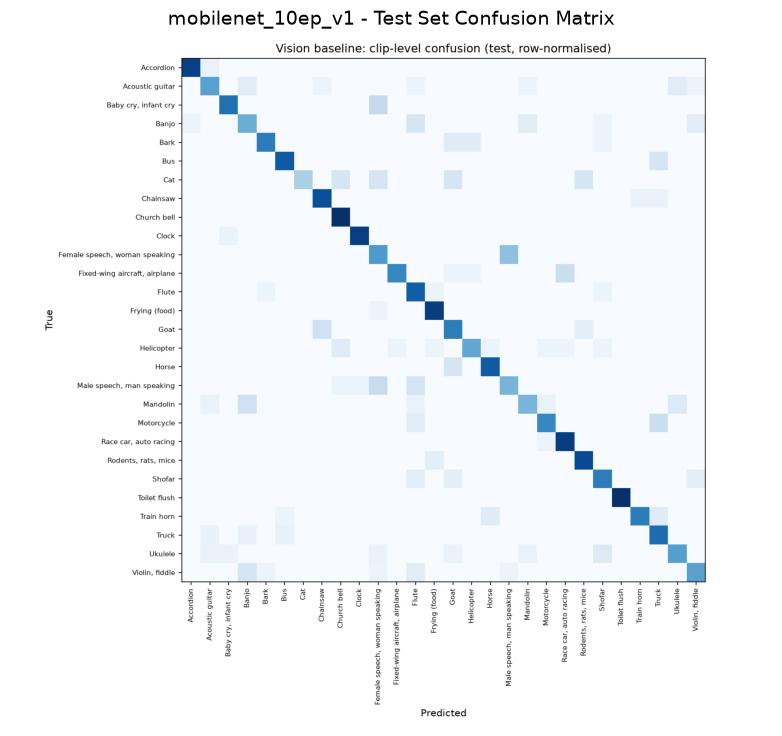

In [5]:
!python -u -m vision.evaluate --run-id {RUN_ID} --batch {BATCH} --workers 0 {WANDB}

import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from vision import config as C

run_dir = C.get_run_dir(RUN_ID)
results_file = run_dir / 'results.json'
if results_file.exists():
    print(f"\n--- EVALUATION METRICS ({RUN_ID}) ---")
    print(results_file.read_text())

confusion_file = run_dir / 'confusion_test.png'
if confusion_file.exists():
    plt.figure(figsize=(10, 9))
    img = mpimg.imread(str(confusion_file))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f'{RUN_ID} - Test Set Confusion Matrix', fontsize=14)
    plt.show()


## 5 · Export Visual Embeddings for Multimodal Fusion
Exports `(N, 10, 512)` float16 embeddings to `_local/drive/embeddings/mobilenet_10ep_v1/`.


In [6]:
!python -u -m vision.export_embeddings --run-id {RUN_ID} --batch {BATCH} --workers 0

from vision import config as C
embed_dir = C.get_embed_dir(RUN_ID)
print(f"Embeddings verified at: {embed_dir}")
if embed_dir.exists():
    for f in sorted(embed_dir.glob('*')):
        print(f"  - {f.name} ({f.stat().st_size:,} bytes)")


train: (3339, 10, 512)
val: (402, 10, 512)
test: (402, 10, 512)
Exported embeddings saved to E:\GitHub-not sorted\NUS-AIS-GCs\Audio-Video-Confidence\_local\drive\embeddings\mobilenet_10ep_v1
Embeddings verified at: E:\GitHub-not sorted\NUS-AIS-GCs\Audio-Video-Confidence\_local\drive\embeddings\mobilenet_10ep_v1
  - SOURCE.txt (40 bytes)
  - test_emb.npy (4,116,608 bytes)
  - test_ids.csv (19,057 bytes)
  - train_emb.npy (34,191,488 bytes)
  - train_ids.csv (158,199 bytes)
  - val_emb.npy (4,116,608 bytes)
  - val_ids.csv (19,065 bytes)


## 6 · Baseline Comparison
Compares `mobilenet_10ep_v1` metrics side-by-side with the default `mobilenet_10ep_v1` baseline.


In [7]:
import json
import pandas as pd
from vision import config as C

baseline_dir = C.get_run_dir('mobilenet_10ep_v1')
current_dir = C.get_run_dir(RUN_ID)

records = []
if (baseline_dir / 'results.json').exists():
    b = json.loads((baseline_dir / 'results.json').read_text())
    records.append({
        'Run ID': 'mobilenet_10ep_v1 (Baseline)',
        'Val Sec F1': f"{b['val']['second_macro_f1']*100:.1f}%",
        'Test Sec F1': f"{b['test']['second_macro_f1']*100:.1f}%",
        'Val Clip F1': f"{b['val']['clip_macro_f1']*100:.1f}%",
        'Test Clip F1': f"{b['test']['clip_macro_f1']*100:.1f}%",
        'Test Clip Acc': f"{b['test']['clip_accuracy']*100:.1f}%"
    })
if (current_dir / 'results.json').exists():
    c = json.loads((current_dir / 'results.json').read_text())
    records.append({
        'Run ID': f'{RUN_ID} (Current)',
        'Val Sec F1': f"{c['val']['second_macro_f1']*100:.1f}%",
        'Test Sec F1': f"{c['test']['second_macro_f1']*100:.1f}%",
        'Val Clip F1': f"{c['val']['clip_macro_f1']*100:.1f}%",
        'Test Clip F1': f"{c['test']['clip_macro_f1']*100:.1f}%",
        'Test Clip Acc': f"{c['test']['clip_accuracy']*100:.1f}%"
    })

if records:
    df = pd.DataFrame(records)
    display(df)


,Run ID,Val Sec F1,Test Sec F1,Val Clip F1,Test Clip F1,Test Clip Acc
0,mobilenet_10ep_v1 (Baseline),62.3%,60.9%,76.3%,71.6%,72.6%
1,mobilenet_10ep_v1 (Current),62.3%,60.9%,76.3%,71.6%,72.6%
